# Lab 10: Odometry vs. gyro localization

**Run A**: course from the encoders (`course_odom`). **Run B**: course from the gyro (`course + gyro_inc`).

Log line written by the robot (no header, one line per cycle):
`t (ms), theta_l (deg), theta_r (deg), gz (mdeg/s), x (m), y (m), course, course_odom, course_gyro (rad)`

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (7, 6), "axes.grid": True})

LOG_A, LOG_B = "lab10_runA_078.txt", "lab10_runB_078.txt"

r, B, gs = 0.042, 0.194, -1    # wheel radius (m), wheel base (m), gyro sign: same as on the robot
ACCEPT = 0.02                  # waypoint acceptance radius = threshold on the robot (m)

# ideal trajectory: start point + the waypoints of the robot program (digits 7 and 8), m
X_ref = np.array([0, 0.25, 0.05, 0.40, 0.40, 0.65, 0.65, 0.40, 0.40, 0.65, 0.65])
Y_ref = np.array([0, 0, -0.40, -0.20, -0.40, -0.40, -0.20, -0.20, 0, 0, -0.20])

In [3]:
columns = ['t', 'theta_l', 'theta_r', 'gz', 'x', 'y', 'course', 'course_odom', 'course_gyro']

# uploading datas from files
df_A = pd.read_csv(LOG_A, header=None, names=columns, sep=r'\s+|\s*,\s*', engine='python')
df_B = pd.read_csv(LOG_B, header=None, names=columns, sep=r'\s+|\s*,\s*', engine='python')

# s -> ms
df_A['t'] /= 1000.0
df_B['t'] /= 1000.0

runs = {
    "A": df_A,
    "B": df_B
}

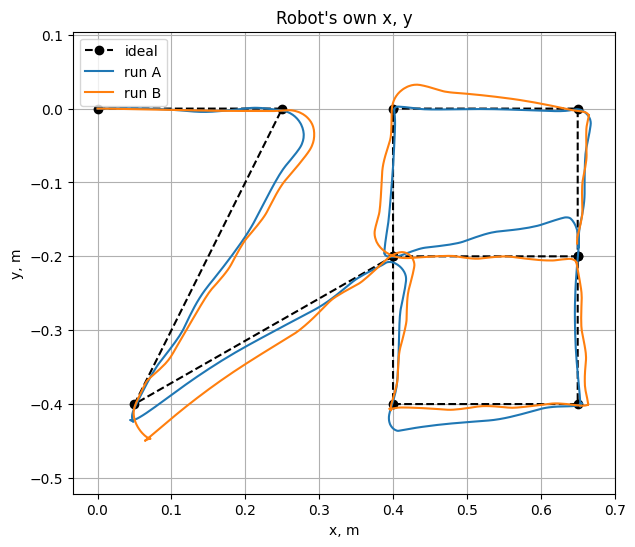

In [4]:
plt.plot(X_ref, Y_ref, "k--o", label="ideal")
for name, log in runs.items():
    plt.plot(log.x, log.y, label="run " + name)
plt.axis("equal"); plt.xlabel("x, m"); plt.ylabel("y, m"); plt.legend(); plt.title("Robot's own x, y")
plt.show()

##Offline recomputation (4 paths)
Both courses are recomputed from the raw sensors of **both** runs:
* encoder course: `(theta_r - theta_l) * r / B`
* gyro course: sum of `gs * (gz - b0) * dt`. The bias `b0` is not in the log, so we get it back from the logged `course_gyro`.

Then `x, y` follow from the path and the course, exactly as on the robot.

In [27]:
runA, runB = runs["A"], runs["B"]

def course_from_encoders(log):
    return (log.theta_r - log.theta_l) * np.pi / 180 * r / B          # rad

def course_from_gyro(log):
    dt = log.t.diff().fillna(0)                                       # s
    # b0 is not in the log: get it back from how the logged course_gyro grows
    b0 = (log.gz - gs * np.degrees(log.course_gyro.diff() / dt) * 1000).median()   # mdeg/s
    rate = gs * (log.gz - b0) / 1000 * np.pi / 180                    # rad/s
    return log.course_gyro[0] + (rate * dt).cumsum()                  # rad

def position(log, course):
    path = (log.theta_r + log.theta_l) / 2 * np.pi / 180 * r         # m
    step = path.diff().fillna(path[0])
    return (step * np.cos(course)).cumsum(), (step * np.sin(course)).cumsum()

# 4 paths: both methods from both logs
cA_enc, cA_gyro = course_from_encoders(runA), course_from_gyro(runA)
cB_enc, cB_gyro = course_from_encoders(runB), course_from_gyro(runB)
xA_enc, yA_enc = position(runA, cA_enc)
xA_gyro, yA_gyro = position(runA, cA_gyro)
xB_enc, yB_enc = position(runB, cB_enc)
xB_gyro, yB_gyro = position(runB, cB_gyro)

# check: on-robot x, y, course = offline recomputation (run A used encoders, run B used gyro)
print("run A: max difference  x %.1f mm,  y %.1f mm,  course %.2f deg" % (
      1000 * abs(runA.x - xA_enc).max(), 1000 * abs(runA.y - yA_enc).max(), np.degrees(abs(runA.course - cA_enc).max())))
print("run B: max difference  x %.1f mm,  y %.1f mm,  course %.2f deg" % (
      1000 * abs(runB.x - xB_gyro).max(), 1000 * abs(runB.y - yB_gyro).max(), np.degrees(abs(runB.course - cB_gyro).max())))


run A: max difference  x 0.0 mm,  y 0.0 mm,  course 0.00 deg
run B: max difference  x 0.0 mm,  y 0.0 mm,  course 0.00 deg


### Comparison table (deliverable 4)

In [34]:
# add segment number and driven step to each log
for log in runs.values():
    seg, i = [], 0
    for x, y in zip(log.x, log.y):
        seg.append(i)
        if i < n_seg - 1 and np.hypot(X_ref[i + 1] - x, Y_ref[i + 1] - y) < ACCEPT:
            i += 1
    log["seg"] = seg
    path = (log.theta_r + log.theta_l) / 2 * np.pi / 180 * r
    log["step"] = path.diff().fillna(path[0])        # distance driven in each cycle, m

# one row per segment
rows = []
for i in range(n_seg):
    row = {"course_ref": np.degrees(course_ref[i]), "path_ref": 100 * path_ref[i]}
    for name, log in runs.items():
        on = log[log.seg == i]                     # samples of this segment
        err = on.course - course_ref[i]
        err = err[abs(err) < 0.2]                  # without the turn at the start
        row["course " + name] = np.degrees(course_ref[i] + err.mean())
        row["d_course " + name] = np.degrees(err.mean())
        row["path " + name] = 100 * on.step.sum()
        row["d_path " + name] = row["path " + name] - row["path_ref"]
    rows.append(row)

table = pd.DataFrame(rows, index=range(1, n_seg + 1))
display(table.round(1))

for name in ["A", "B"]:
    print("run %s: mean |d_course| = %.1f deg, total path error = %.1f %%"
          % (name, table["d_course " + name].abs().mean(), 100 * table["d_path " + name].sum() / table.path_ref.sum()))

,course_ref,path_ref,course A,d_course A,path A,d_path A,course B,d_course B,path B,d_path B
1,0.0,25.0,0.1,0.1,23.5,-1.5,-0.8,-0.8,23.1,-1.9
2,-116.6,44.7,-121.2,-4.7,48.2,3.5,-121.1,-4.6,50.7,6.0
3,29.7,40.3,31.6,1.9,43.5,3.2,34.9,5.1,46.8,6.5
4,-90.0,20.0,-93.8,-3.8,20.0,0.0,-93.7,-3.7,22.9,2.9
5,0.0,25.0,5.1,5.1,29.2,4.2,1.5,1.5,26.5,1.5
6,90.0,20.0,90.6,0.6,20.6,0.6,93.5,3.5,21.3,1.3
7,180.0,25.0,185.7,5.7,30.1,5.1,179.5,-0.5,24.6,-0.4
8,90.0,20.0,86.3,-3.7,21.0,1.0,86.3,-3.7,21.6,1.6
9,0.0,25.0,-1.0,-1.0,24.8,-0.2,-5.6,-5.6,27.1,2.1
10,-90.0,20.0,-94.2,-4.2,21.4,1.4,-93.4,-3.4,20.7,0.7


run A: mean |d_course| = 3.1 deg, total path error = 6.5 %
run B: mean |d_course| = 3.2 deg, total path error = 7.6 %


### Final errors (relative to the last waypoint)

In [36]:
END_MEASURED = {"A": None, "B": None}

for name, log in runs.items():
    end = log.iloc[-1]
    print("run %s (robot's own estimate): position error %.1f cm, course error %.1f deg"
          % (name, 100 * np.hypot(X_ref[-1] - end.x, Y_ref[-1] - end.y),
             np.degrees(wrap(end.course - course_ref[-1]))))

run A (robot's own estimate): position error 1.2 cm, course error -1.1 deg
run B (robot's own estimate): position error 1.7 cm, course error 0.3 deg


### Course over time
`course_ref` is a staircase: one step per segment.

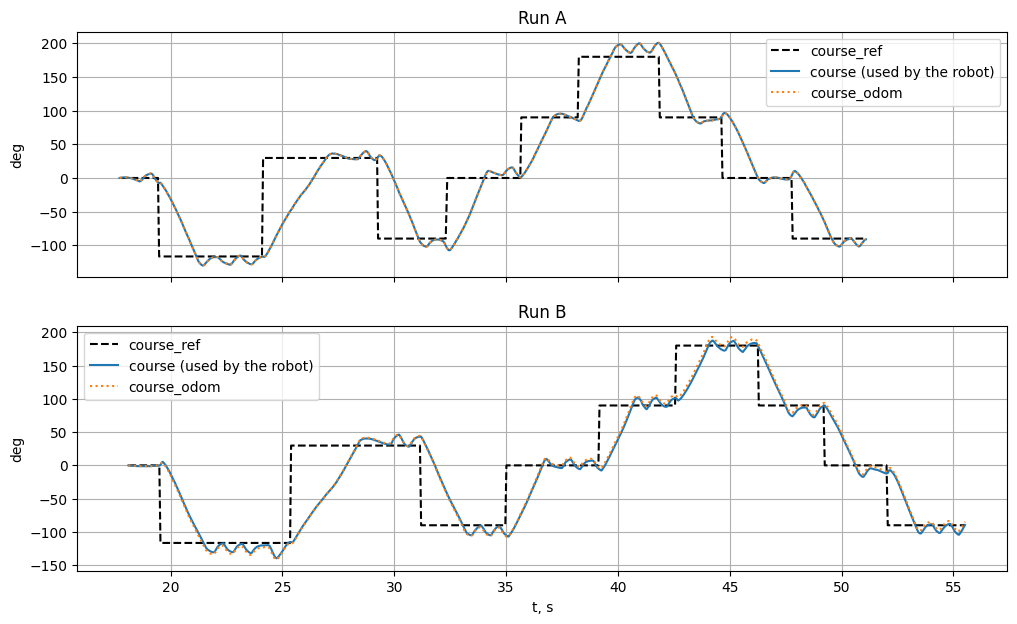

In [37]:
fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for a, (name, log) in zip(ax, runs.items()):
    a.plot(log.t, np.degrees(np.unwrap(course_ref)[log.seg]), "k--", label="course_ref")
    a.plot(log.t, np.degrees(log.course), label="course (used by the robot)")
    a.plot(log.t, np.degrees(log.course_odom), ":", label="course_odom")
    a.set_ylabel("deg"); a.set_title("Run " + name); a.legend()
ax[1].set_xlabel("t, s")
plt.show()

## Step 4.5: Error growth

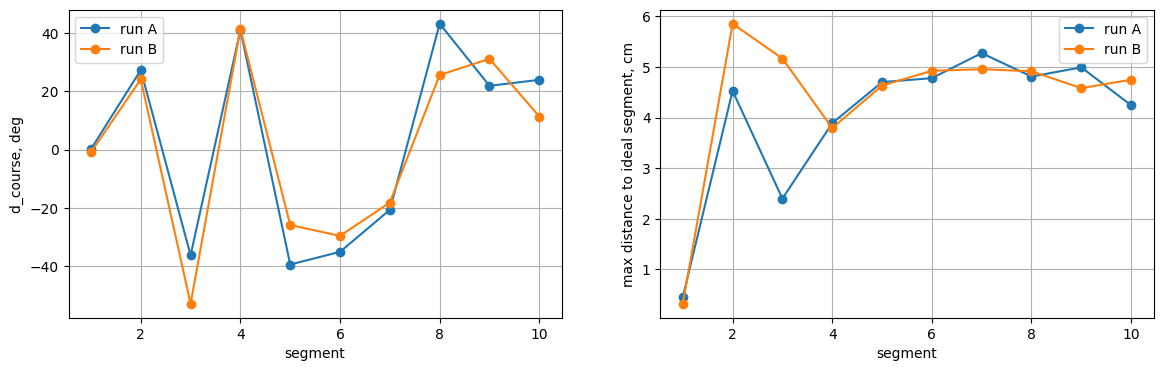

In [39]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for name, seg in (("A", seg_A), ("B", seg_B)):
    ax[0].plot(seg.index, seg.d_course, "o-", label="run " + name)
    ax[1].plot(seg.index, seg.dist, "o-", label="run " + name)
ax[0].set_ylabel("d_course, deg"); ax[1].set_ylabel("max distance to ideal segment, cm")
for a in ax:
    a.set_xlabel("segment"); a.legend()
plt.show()